In [11]:
import csv

with open("../data/raw/phone_sales_data.csv",
          newline="", encoding="utf-8") as f:

    reader = csv.reader(f)
    header = next(reader)

    print("Columns:", header)

    for i, row in enumerate(reader):
        if i < 10:
            print(row)

Columns: ['Record_ID', 'Week_Start_Date', 'City', 'Phone_Segment', 'Sales_Channel', 'Avg_Price_INR', 'Discount_Percent', 'Ad_Spend_INR', 'Weekly_Footfall', 'Customer_Rating', 'Units_Sold']
['M1191', '2026-02-02', 'Delhi', 'Premium', 'Online', '83100', '12.6', '39000', '764', '4.4', '36']
['M1136', '2025-06-09', 'Lucknow', 'Mid_Range', 'Retail_Store', '25300', '11.8', '52500', '761', '3.7', '45']
['M1203', '2025-12-22', 'Pune', 'Budget', 'Online', '9800', '9.8', '19000', '664', '4.0', '30']
['M1126', '2026-04-20', 'Mumbai', 'Mid_Range', 'Online', '34100', '2.9', '', '1098', '4.1', '36']
['M1220', '2025-08-11', 'Lucknow', 'Mid_Range', 'Online', '28800', '13.9', '26000', '1267', '4.2', '56']
['M1184', '2026-06-08', 'Delhi', 'Premium', 'Retail_Store', '51500', '12.8', '21500', '1299', '3.9', '64']
['M1095', '2026-09-07', 'Jaipur', 'Budget', 'Online', '7700', '12.2', '24500', '1110', '3.9', '44']
['M1248', '2026-04-27', 'Jaipur', 'Mid_Range', 'Online', '19000', '10.9', '18500', '990', '4.5'

In [1]:
#loding raw data
import pandas as pd
import numpy as np

# Load the raw dataset
df = pd.read_csv("../data/raw/phone_sales_data.csv")

# Keep an untouched copy of original data
raw_df = df.copy()

print("Raw shape:", df.shape)

#__________________________________________________________________________________________________________________

#FIRST LOOK
print(df.info())

print("\nMissing values per column:\n")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumeric summary:\n")
print(df.describe())

#__________________________________________________________________________________________________________________

#REMOVE DUPLICATE ROWS
df = df.drop_duplicates().reset_index(drop=True)

print("After removing duplicates:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

#__________________________________________________________________________________________________________________

#FIX INCONSISTENT TEXT (extra spaces, upper/lower case)
cat_cols = ["City", "Phone_Segment", "Sales_Channel"]

for col in cat_cols:
    df[col] = df[col].str.strip().str.title()

print("City values:\n", df["City"].value_counts(dropna=False))

print("\nPhone segments:\n", df["Phone_Segment"].value_counts(dropna=False))

print("\nSales channels:\n", df["Sales_Channel"].value_counts(dropna=False))

#__________________________________________________________________________________________________________________

#HANDLE IMPOSSIBLE VALUES
# Discount percentage should be between 0 and 100

bad_discount = (
    (df["Discount_Percent"] < 0) |
    (df["Discount_Percent"] > 100)
)

print("Invalid discounts:", bad_discount.sum())

# Replace invalid discounts with NaN
df.loc[bad_discount, "Discount_Percent"] = np.nan

#__________________________________________________________________________________________________________________

#FIX DATA TYPES
df["Week_Start_Date"] = pd.to_datetime(
    df["Week_Start_Date"],
    errors="coerce"
)

print(df.dtypes)

#__________________________________________________________________________________________________________________

#HANDLE MISSING VALUES

#    Categorical column – Mode
df["Sales_Channel"] = df["Sales_Channel"].fillna(
    df["Sales_Channel"].mode()[0]
)

#    Numerical columns – Median
numeric_cols = [
    "Discount_Percent",
    "Ad_Spend_INR",
    "Weekly_Footfall",
    "Customer_Rating"
]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

#__________________________________________________________________________________________________________________ 
   
#FINAL CHECKS

print("\nClean shape:", df.shape)

print("\nMissing values left:")
print(df.isna().sum())

print("\nTotal missing values:", df.isna().sum().sum())

print("\nDuplicate rows left:", df.duplicated().sum())

print("\nDuplicate IDs left:", df["Record_ID"].duplicated().sum())

print("\nFinal statistical summary:")
print(df.describe())

#__________________________________________________________________________________________________________________ 

#SAVING CLEANED DATA

df.to_csv(
    "../data/processed/phone_sales_cleaned.csv",
    index=False
)

print("Cleaned dataset and saved successfully!")






Raw shape: (255, 11)
<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Record_ID         255 non-null    str    
 1   Week_Start_Date   255 non-null    str    
 2   City              255 non-null    str    
 3   Phone_Segment     255 non-null    str    
 4   Sales_Channel     250 non-null    str    
 5   Avg_Price_INR     255 non-null    int64  
 6   Discount_Percent  255 non-null    float64
 7   Ad_Spend_INR      250 non-null    float64
 8   Weekly_Footfall   251 non-null    float64
 9   Customer_Rating   249 non-null    float64
 10  Units_Sold        255 non-null    int64  
dtypes: float64(4), int64(2), str(5)
memory usage: 22.0 KB
None

Missing values per column:

Record_ID           0
Week_Start_Date     0
City                0
Phone_Segment       0
Sales_Channel       5
Avg_Price_INR       0
Discount_Percent    0
Ad_Spend_INR        5
Weekl

In [8]:
import pandas as pd

df = pd.read_csv("../data/processed/phone_sales_cleaned.csv")

print("Dataset loaded successfully!")
print(df.shape)

print("Minimum Footfall:", df["Weekly_Footfall"].min())
print("Maximum Footfall:", df["Weekly_Footfall"].max())
print("\nFootfall Statistics:")
print(df["Weekly_Footfall"].describe())

Dataset loaded successfully!
(250, 11)
Minimum Footfall: 150.0
Maximum Footfall: 1788.0

Footfall Statistics:
count     250.000000
mean      925.348000
std       345.738437
min       150.000000
25%       686.250000
50%       933.500000
75%      1171.250000
max      1788.000000
Name: Weekly_Footfall, dtype: float64


In [ ]:
#CREATING NEW COLUMNS

# 1. Calculate estimated revenue
df["Estimated_Revenue_INR"] = (
    df["Units_Sold"] * df["Avg_Price_INR"]
)

# 2. Classify sales status using if-else
def classify_sales(units):
    if units < 25:
        return "At Risk"
    else:
        return "Normal"

df["Sales_Status"] = df["Units_Sold"].apply(classify_sales)

# 3. Categorize weekly footfall
df["Footfall_Band"] = pd.cut(
    df["Weekly_Footfall"],
    bins=3,
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print("Three new columns created successfully!")

Three new columns created successfully!


In [ ]:
print(df["Sales_Status"].value_counts())

Sales_Status
Normal     216
At Risk     34
Name: count, dtype: int64


In [27]:
print(df[[
    "Estimated_Revenue_INR",
    "Sales_Status",
    "Footfall_Band"
]].head(10))

   Estimated_Revenue_INR Sales_Status Footfall_Band
0                2991600       Normal        Medium
1                1138500       Normal        Medium
2                 294000       Normal           Low
3                1227600       Normal        Medium
4                1612800       Normal          High
5                3296000       Normal          High
6                 338800       Normal        Medium
7                1007000       Normal        Medium
8                 877400       Normal        Medium
9                 224400      At Risk        Medium


In [30]:
df.to_csv(
    "../data/processed/phone_sales_cleaned_added_columns.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [33]:
df.head()

,Record_ID,Week_Start_Date,City,Phone_Segment,Sales_Channel,Avg_Price_INR,Discount_Percent,Ad_Spend_INR,Weekly_Footfall,Customer_Rating,Units_Sold,Estimated_Revenue_INR,Sales_Status,Footfall_Band
0,M1191,2026-02-02,Delhi,Premium,Online,83100,12.6,39000.0,764.0,4.4,36,2991600,Normal,Medium
1,M1136,2025-06-09,Lucknow,Mid_Range,Retail_Store,25300,11.8,52500.0,761.0,3.7,45,1138500,Normal,Medium
2,M1203,2025-12-22,Pune,Budget,Online,9800,9.8,19000.0,664.0,4.0,30,294000,Normal,Low
3,M1126,2026-04-20,Mumbai,Mid_Range,Online,34100,2.9,43500.0,1098.0,4.1,36,1227600,Normal,Medium
4,M1220,2025-08-11,Lucknow,Mid_Range,Online,28800,13.9,26000.0,1267.0,4.2,56,1612800,Normal,High


In [34]:
df.describe()

,Avg_Price_INR,Discount_Percent,Ad_Spend_INR,Weekly_Footfall,Customer_Rating,Units_Sold,Estimated_Revenue_INR
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000,2.500000e+02
mean,24982.400000,9.566000,43468.000000,925.348000,4.044800,40.636000,9.733828e+05
std,22599.408472,5.692975,21098.568063,345.738437,0.372111,14.804465,8.857638e+05
min,7100.000000,0.000000,5000.000000,150.000000,3.000000,5.000000,7.500000e+04
25%,11000.000000,5.225000,27000.000000,686.250000,3.800000,30.250000,4.136250e+05
50%,15950.000000,9.200000,43500.000000,933.500000,4.000000,40.000000,6.410000e+05
75%,28900.000000,13.475000,61875.000000,1171.250000,4.300000,51.000000,1.216925e+06
max,107000.000000,24.700000,80000.000000,1788.000000,4.900000,78.000000,4.461600e+06


# Exploratory data analysis (EDA)

Q1. What does Units_Sold look like overall?

In [ ]:
#This analysis examines the overall distribution of units sold, including the typical sales volume, variation, minimum sales and maximum sales.

In [37]:
print(df["Units_Sold"].describe().round(2))

count    250.00
mean      40.64
std       14.80
min        5.00
25%       30.25
50%       40.00
75%       51.00
max       78.00
Name: Units_Sold, dtype: float64


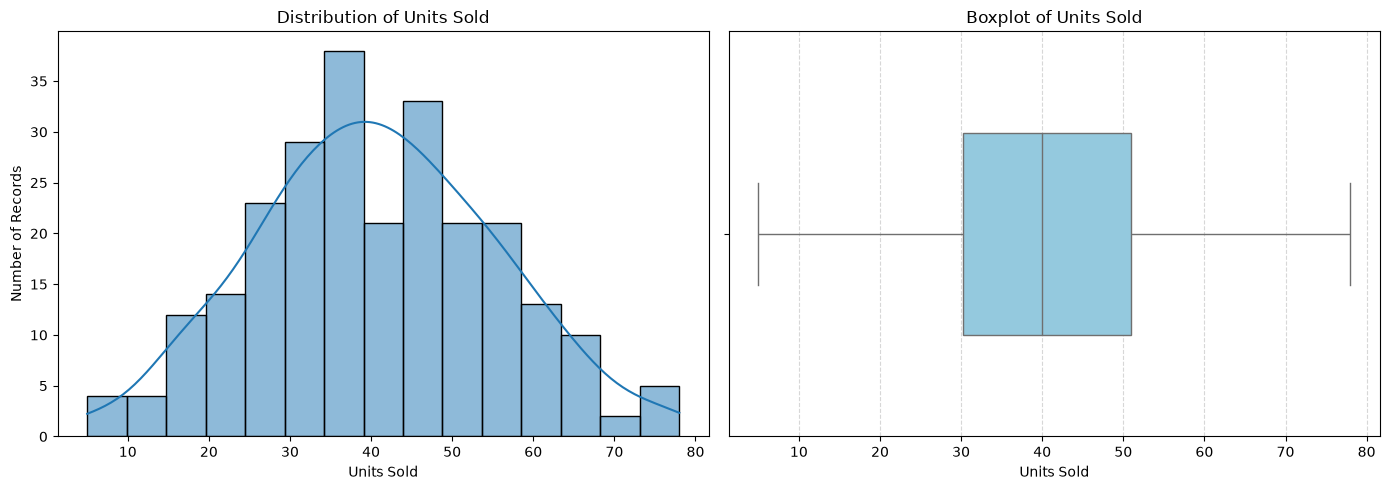

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram
sns.histplot(
    data=df,
    x="Units_Sold",
    bins=15,
    kde=True,
    ax=ax[0]
)

ax[0].set_title("Distribution of Units Sold")
ax[0].set_xlabel("Units Sold")
ax[0].set_ylabel("Number of Records")


# 2. Boxplot
sns.boxplot(
    data=df,
    x="Units_Sold",
    ax=ax[1],
    color="skyblue",
    width=0.5
)

ax[1].set_title("Boxplot of Units Sold")
ax[1].set_xlabel("Units Sold")
ax[1].set_ylabel("")

ax[1].grid(axis="x", linestyle="--", alpha=0.5)

# Final layout and save
plt.tight_layout()
plt.savefig("../images/01_overall_sales.png", dpi=300, bbox_inches="tight")
plt.show()

Q2. Do Discount_Percent, Weekly_Footfall, Customer_Rating and Ad_Spend_INR affect Units_Sold?

In [ ]:
#This analysis explores the relationship between four business factors and the number of phones sold. Scatter plots and correlation analysis will be used to identify possible relationships.

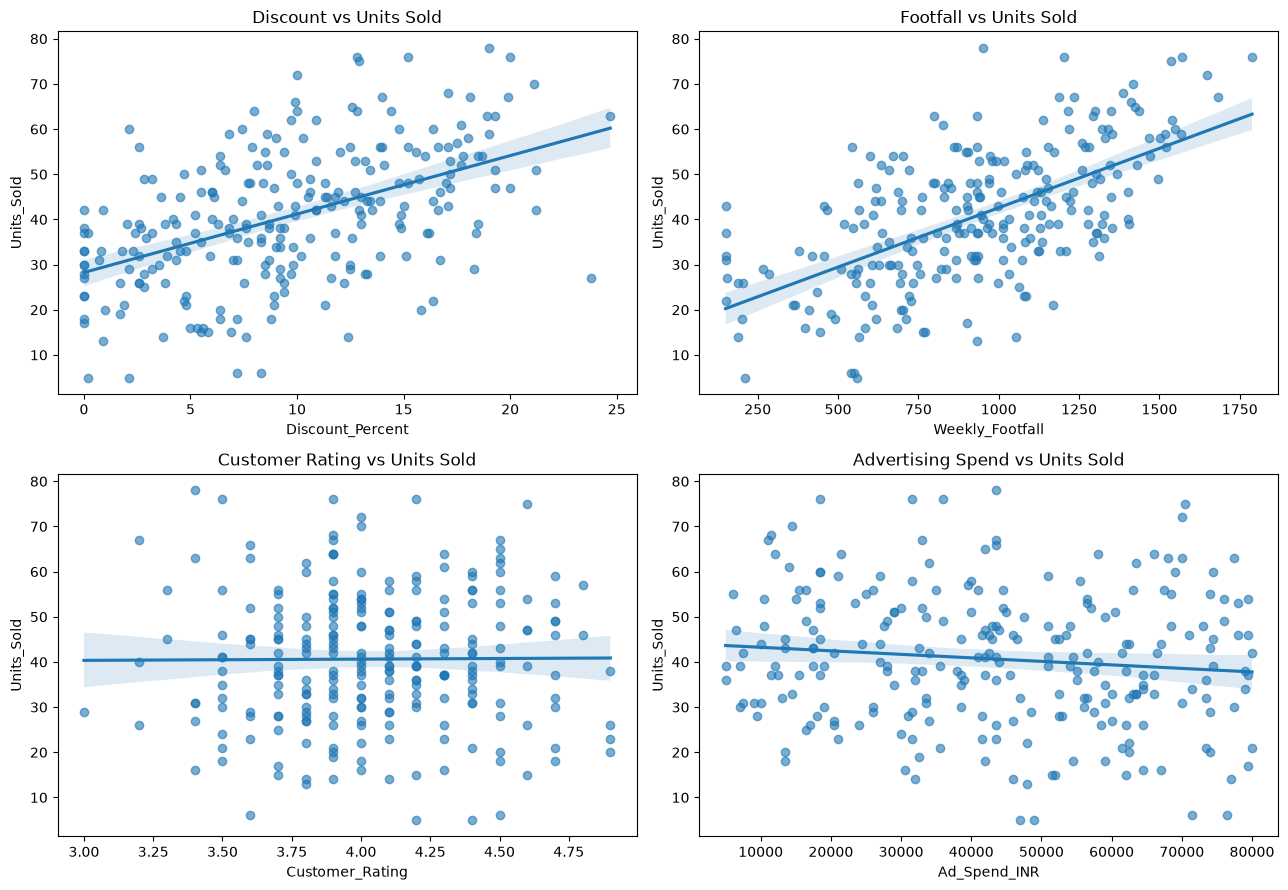

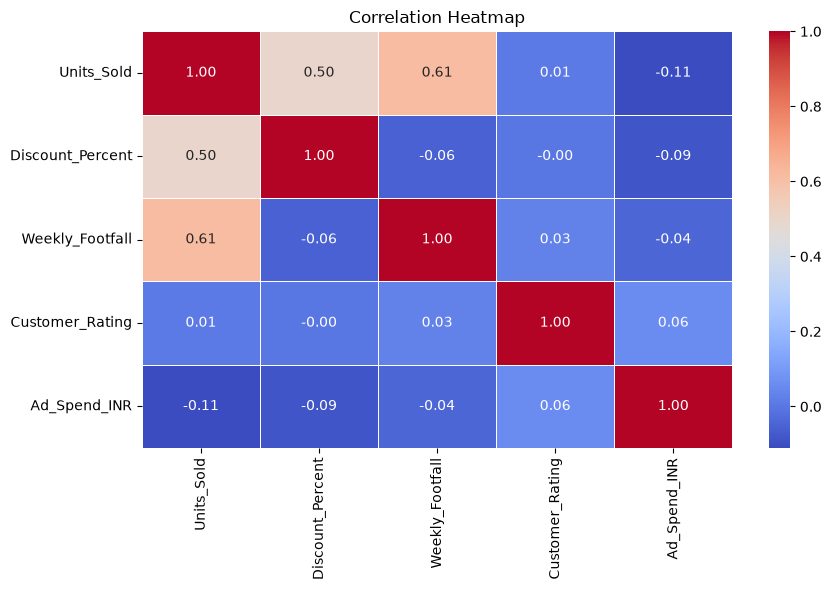

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# 1. Discount vs Units Sold
sns.regplot(
    data=df,
    x="Discount_Percent",
    y="Units_Sold",
    ax=ax[0, 0],
    scatter_kws={"alpha": 0.6}
)
ax[0, 0].set_title("Discount vs Units Sold")

# 2. Footfall vs Units Sold
sns.regplot(
    data=df,
    x="Weekly_Footfall",
    y="Units_Sold",
    ax=ax[0, 1],
    scatter_kws={"alpha": 0.6}
)
ax[0, 1].set_title("Footfall vs Units Sold")

# 3. Customer Rating vs Units Sold
sns.regplot(
    data=df,
    x="Customer_Rating",
    y="Units_Sold",
    ax=ax[1, 0],
    scatter_kws={"alpha": 0.6}
)
ax[1, 0].set_title("Customer Rating vs Units Sold")

# 4. Advertising Spend vs Units Sold
sns.regplot(
    data=df,
    x="Ad_Spend_INR",
    y="Units_Sold",
    ax=ax[1, 1],
    scatter_kws={"alpha": 0.6}
)
ax[1, 1].set_title("Advertising Spend vs Units Sold")

plt.tight_layout()
plt.savefig("../images/02_sales_relationships.png",
            dpi=300, bbox_inches="tight")
plt.show()

#correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("../images/03_correlation_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()

Q3. Does Units_Sold differ by City, Phone_Segment and Sales_Channel?

In [17]:
#This analysis compares the average number of units sold across different cities, phone segments and sales channels to identify differences in sales performance.

In [20]:
#Average sales by City
city_sales = df.groupby("City")["Units_Sold"].mean().sort_values(
    ascending=False
)

print(city_sales.round(2))

#Average sales by Phone Segment
segment_sales = df.groupby(
    "Phone_Segment"
)["Units_Sold"].mean().sort_values(ascending=False)

print(segment_sales.round(2))

#Average sales by Sales Channel
channel_sales = df.groupby(
    "Sales_Channel"
)["Units_Sold"].mean().sort_values(ascending=False)

print(channel_sales.round(2))

City
Jaipur     44.40
Pune       41.26
Delhi      41.26
Lucknow    39.58
Mumbai     38.84
Name: Units_Sold, dtype: float64
Phone_Segment
Budget       41.48
Mid_Range    40.29
Premium      38.48
Name: Units_Sold, dtype: float64
Sales_Channel
Distributor     40.86
Online          40.82
Retail_Store    40.29
Name: Units_Sold, dtype: float64


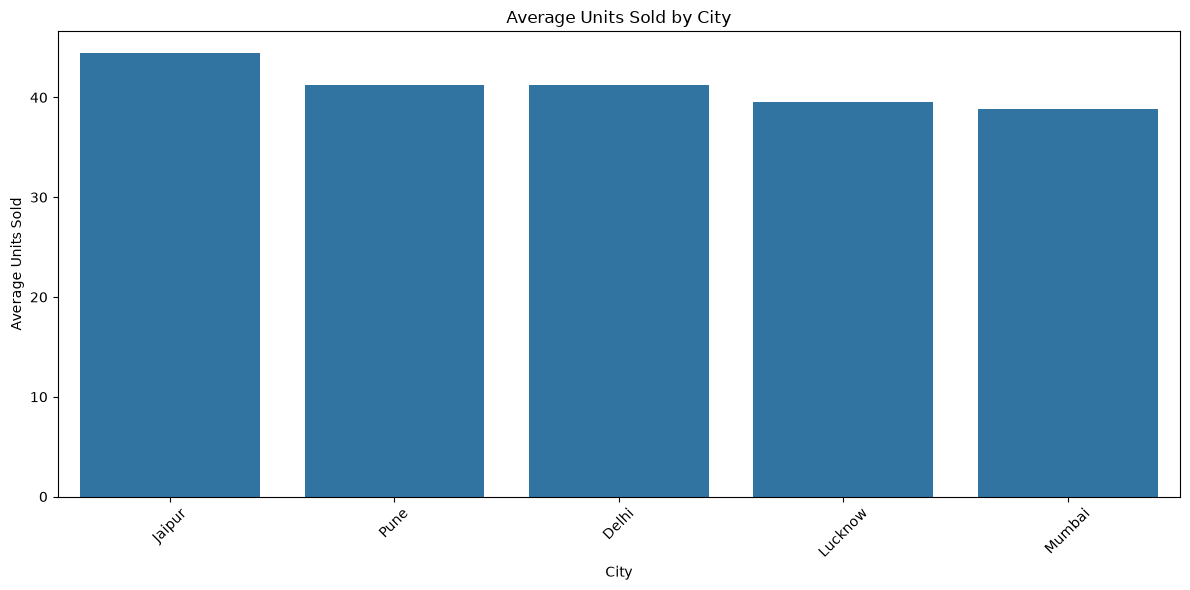

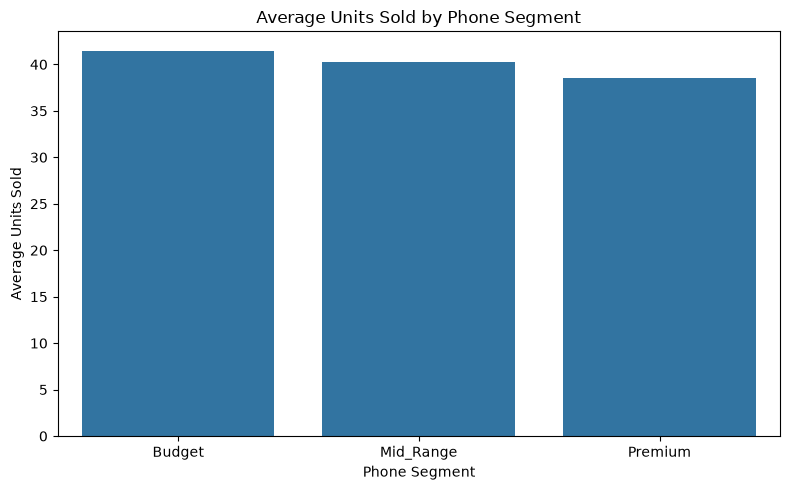

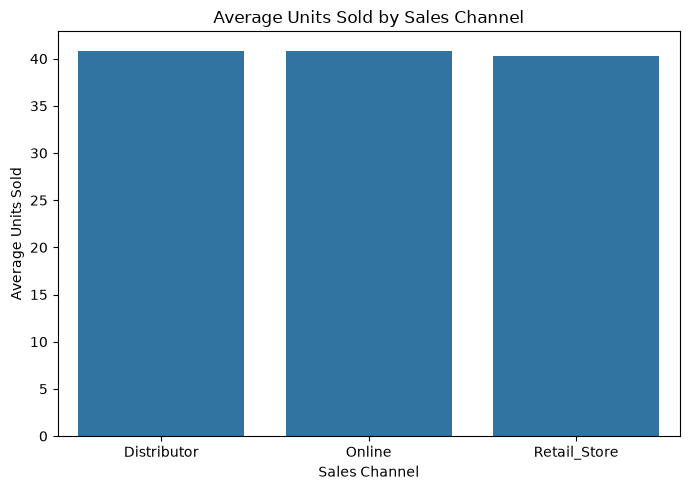

In [21]:
#Average sales by City
plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_sales.index,
    y=city_sales.values
)

plt.title("Average Units Sold by City")
plt.xlabel("City")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../images/04_sales_by_city.png",
            dpi=300, bbox_inches="tight")
plt.show()

#Average sales by Phone Segment
plt.figure(figsize=(8, 5))

sns.barplot(
    x=segment_sales.index,
    y=segment_sales.values
)

plt.title("Average Units Sold by Phone Segment")
plt.xlabel("Phone Segment")
plt.ylabel("Average Units Sold")
plt.tight_layout()

plt.savefig("../images/05_sales_by_segment.png",
            dpi=300, bbox_inches="tight")
plt.show()


#Average sales by Sales Channel
plt.figure(figsize=(7, 5))

sns.barplot(
    x=channel_sales.index,
    y=channel_sales.values
)

plt.title("Average Units Sold by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Average Units Sold")
plt.tight_layout()

plt.savefig("../images/06_sales_by_channel.png",
            dpi=300, bbox_inches="tight")
plt.show()

Q4. Which records need attention?

In [ ]:
#This analysis identifies records with low sales. Any record with fewer than 25 units sold is classified as "At Risk", while records with 25 or more units sold are classified as "Normal".

In [22]:
status_counts = df["Sales_Status"].value_counts()

print(status_counts)

Sales_Status
Normal     216
At Risk     34
Name: count, dtype: int64


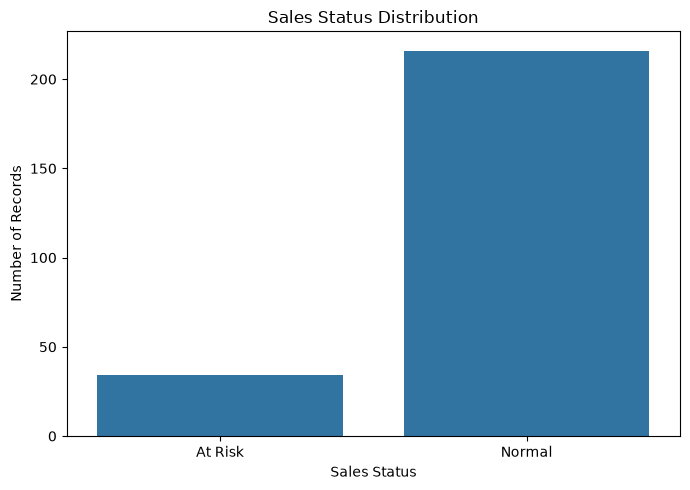

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Sales_Status",
    order=["At Risk", "Normal"]
)

plt.title("Sales Status Distribution")
plt.xlabel("Sales Status")
plt.ylabel("Number of Records")

plt.tight_layout()

plt.savefig("../images/07_sales_status.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [24]:
at_risk_records = df[df["Sales_Status"] == "At Risk"]

print("Total At Risk Records:", len(at_risk_records))

at_risk_records.head(10)

Total At Risk Records: 34


,Record_ID,Week_Start_Date,City,Phone_Segment,Sales_Channel,Avg_Price_INR,Discount_Percent,Ad_Spend_INR,Weekly_Footfall,Customer_Rating,Units_Sold,Estimated_Revenue_INR,Sales_Status,Footfall_Band
9,M1067,2025-07-07,Delhi,Budget,Retail_Store,10200,4.7,62500.0,727.0,4.0,22,224400,At Risk,Medium
34,M1182,2026-06-15,Mumbai,Mid_Range,Online,18500,5.0,67000.0,683.0,4.3,16,296000,At Risk,Low
38,M1027,2026-05-18,Lucknow,Budget,Online,9600,6.9,62000.0,764.0,4.2,15,144000,At Risk,Medium
44,M1159,2024-12-16,Lucknow,Mid_Range,Retail_Store,18800,8.9,21000.0,585.0,3.6,23,432400,At Risk,Low
50,M1016,2026-09-07,Mumbai,Budget,Online,14400,5.3,30500.0,396.0,3.4,16,230400,At Risk,Low
52,M1065,2026-08-03,Delhi,Mid_Range,Distributor,25800,15.8,74000.0,410.0,4.5,20,516000,At Risk,Low
62,M1204,2026-08-10,Delhi,Premium,Retail_Store,93200,3.7,77000.0,188.0,3.8,14,1304800,At Risk,Low
67,M1216,2026-11-02,Mumbai,Mid_Range,Distributor,27000,8.3,76500.0,551.0,3.6,6,162000,At Risk,Low
74,M1017,2025-02-17,Delhi,Budget,Online,12900,0.0,13500.0,617.0,3.5,18,232200,At Risk,Low
84,M1217,2026-03-02,Lucknow,Mid_Range,Online,28900,4.8,31500.0,1079.0,4.1,23,664700,At Risk,Medium


In [3]:

# Average sales by City
print("Average Sales by City:")
print(df.groupby("City")["Units_Sold"].mean().sort_values(ascending=False))

# Average sales by Phone Segment
print("\nAverage Sales by Phone Segment:")
print(df.groupby("Phone_Segment")["Units_Sold"].mean().sort_values(ascending=False))

# Average sales by Sales Channel
print("\nAverage Sales by Sales Channel:")
print(df.groupby("Sales_Channel")["Units_Sold"].mean().sort_values(ascending=False))

# At-risk records by City
print("\nAt Risk Records by City:")
print(df[df["Sales_Status"] == "At Risk"]["City"].value_counts())

# Correlation with Units Sold
print("\nCorrelation with Units Sold:")
print(df[[
    "Discount_Percent",
    "Weekly_Footfall",
    "Customer_Rating",
    "Ad_Spend_INR",
    "Units_Sold"
]].corr()["Units_Sold"].sort_values(ascending=False))


Average Sales by City:
City
Jaipur     44.400000
Pune       41.261905
Delhi      41.260274
Lucknow    39.581395
Mumbai     38.835821
Name: Units_Sold, dtype: float64

Average Sales by Phone Segment:
Phone_Segment
Budget       41.483607
Mid_Range    40.294737
Premium      38.484848
Name: Units_Sold, dtype: float64

Average Sales by Sales Channel:
Sales_Channel
Distributor     40.857143
Online          40.817460
Retail_Store    40.292135
Name: Units_Sold, dtype: float64

At Risk Records by City:
City
Mumbai     11
Delhi      10
Lucknow     7
Pune        6
Name: count, dtype: int64

Correlation with Units Sold:
Units_Sold          1.000000
Weekly_Footfall     0.613839
Discount_Percent    0.497449
Customer_Rating     0.006909
Ad_Spend_INR       -0.110959
Name: Units_Sold, dtype: float64


In [6]:
print(df[df["Sales_Status"] == "At Risk"]["City"].value_counts())

City
Mumbai     11
Delhi      10
Lucknow     7
Pune        6
Name: count, dtype: int64


# Insights and Recommendations for the Sales Manager

## 1. Key Insights

**1. City-wise Sales Performance**

Jaipur recorded the highest average sales of 44.40 units, while Mumbai recorded the lowest average sales of 38.84 units. This indicates differences in sales performance across cities.

**2. Phone Segment Performance**

Budget phones recorded the highest average sales of 41.48 units, followed by Mid-Range phones at 40.29 units and Premium phones at 38.48 units.

**3. Sales Channel Performance**

Distributor sales had the highest average of 40.86 units, followed closely by Online sales at 40.82 units and Retail Store sales at 40.29 units. All three channels showed relatively similar performance.

**4. Factors Affecting Sales**

The correlation analysis showed:
- Weekly Footfall has a positive correlation of 0.614 with Units Sold.
- Discount Percentage has a positive correlation of 0.497.
- Customer Rating has almost no linear correlation (0.007).
- Advertising Spend has a weak negative correlation (-0.111).

This suggests that customer footfall and discounts have stronger positive relationships with sales than the other factors analysed. However, correlation does not establish causation.

**5. At-Risk Sales Analysis**

Out of 250 records, 34 records (13.6%) were classified as At Risk because they had fewer than 25 units sold.

City-wise distribution:
- Mumbai: 11 records
- Delhi: 10 records
- Lucknow: 7 records
- Pune: 6 records
- Jaipur: 0 records

Mumbai and Delhi account for most of the at-risk records and require additional attention.

## 2. Recommendations

1. **Improve City-wise Performance:** Investigate the reasons for lower sales in Mumbai and apply successful sales practices observed in Jaipur.

2. **Focus on Budget Phones:** Maintain adequate stock of budget phones because they have the highest average sales.

3. **Promote Premium Phones:** Introduce targeted promotional offers and marketing campaigns to improve premium phone sales.

4. **Increase Customer Footfall:** Organise promotional events, improve store visibility and use local marketing strategies to attract more customers.

5. **Optimise Discount Strategies:** Use discounts strategically and monitor their impact on sales to avoid unnecessary reductions in profit margins.

6. **Evaluate Advertising Effectiveness:** Review advertising campaigns and compare their expenditure with the sales generated before increasing the advertising budget.

7. **Monitor At-Risk Sales:** Give special attention to Mumbai and Delhi, identify the reasons for low sales and take corrective action.

## 3. Conclusion

The analysis of 250 phone sales records provided useful insights into city-wise performance, phone segment preferences, sales channels and factors associated with sales. Jaipur and Budget phones showed the highest average sales performance. Weekly Footfall and Discount Percentage had the strongest positive relationships with Units Sold among the factors analysed.

The sales manager should focus on increasing customer footfall, improving underperforming cities, managing promotional strategies and monitoring at-risk sales records. These actions can help improve sales performance and support better business decisions.